# Distribution et saisonnalité
Objectif : Intégrer de la visualisation aux données de notre projet

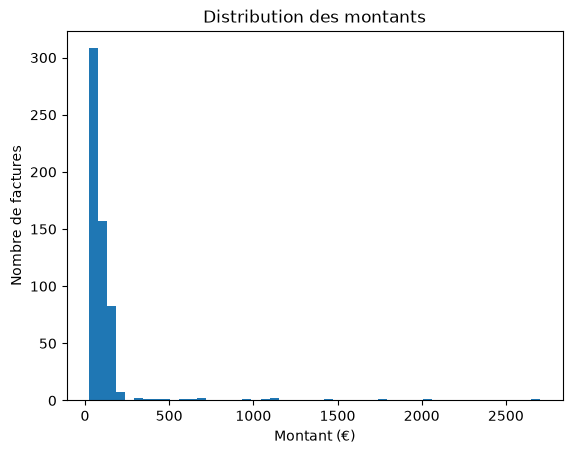

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

df_contrats = pd.read_csv("../data/contrats.csv")
df_factures = pd.read_csv("../data/factures.csv", parse_dates=["date_facture"])
etiquettes = df_factures.pop("anomalie")

df_factures["montant"].plot(kind="hist", bins=50)   # histogramme en 50 barres
plt.title("Distribution des montants")
plt.xlabel("Montant (€)")
plt.ylabel("Nombre de factures")
plt.show()

## Distribution des consommations

*histogramme des consommations*


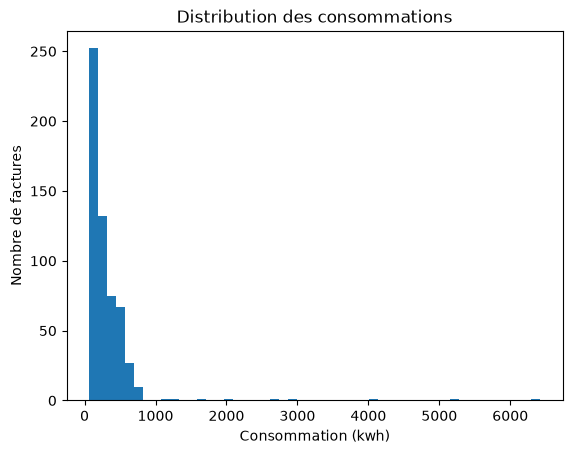

In [42]:
df_factures["consommation_kwh"].plot(kind="hist", bins=50)   # histogramme en 50 barres
plt.title("Distribution des consommations")
plt.xlabel("Consommation (kwh)")
plt.ylabel("Nombre de factures")
plt.show()

On remarque que presque toutes les factures sont sous 800 kWh, et une poignée de valeurs isolées s’étalent jusqu’à 6 400 kWh

***Moyenne et médiane de la consommation***

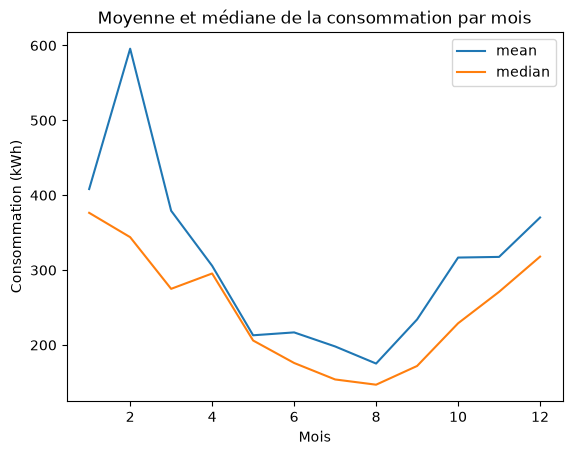

In [43]:
df_factures["mois"] = df_factures["date_facture"].dt.month
df_conso = df_factures.groupby("mois")["consommation_kwh"].agg(["mean", "median"])
df_conso.plot()
plt.title("Moyenne et médiane de la consommation par mois")
plt.xlabel("Mois")
plt.ylabel("Consommation (kWh)")
plt.show()


On consomme le plus en décembre, janvier et février, et le moins en juillet et août.

***Contrôle si identifiants en double***
Si un contrat apparaissait en double, ses factures seraient dupliquées par la jointure : le nombre de lignes doit rester 572.

In [44]:
df = pd.merge(df_factures, df_contrats, left_on="identifiant_contrat",
              right_on="identifiant", how="left", validate="many_to_one")
print("Nombre de factures : ",len(df))

Nombre de factures :  572


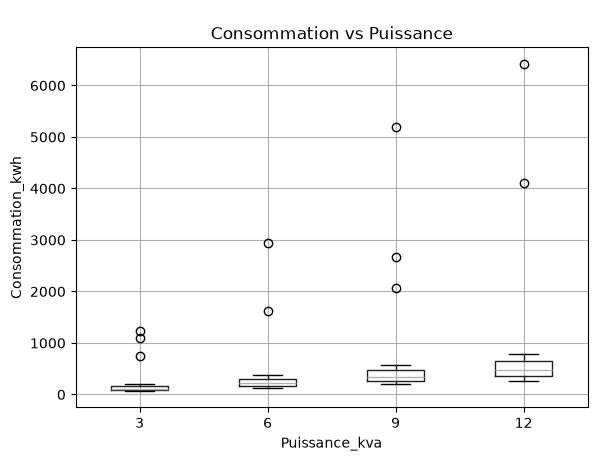

In [ ]:
bx=df.boxplot(column="consommation_kwh", by="puissance_kva")
plt.suptitle(" ")
bx.set_title("Consommation vs Puissance")
bx.set_xlabel("Puissance_kva")
bx.set_ylabel("Consommation_kWh")
plt.show()



La distribution globale des consommations et des montants facturés est concentrée autour de valeurs habituelles, avec quelques valeurs extrêmes pouvant constituer des anomalies. L’analyse mensuelle sur 2025 met en évidence une saisonnalité marquée, tandis que la médiane apparaît plus représentative que la moyenne, car moins influencée par les valeurs extrêmes. La comparaison selon la puissance souscrite (kVA) montre qu’une même consommation peut être normale pour un contrat et atypique pour un autre. La détection d’anomalies devra donc s’appuyer sur des seuils adaptés à chaque groupe de contrats et à la saisonnalité, plutôt que sur des seuils globaux appliqués à l’ensemble des factures.